Necessary Imports

In [3]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report, precision_recall_fscore_support
from sklearn.feature_selection import mutual_info_classif
from scipy.sparse import csr_matrix
from bs4 import BeautifulSoup
import re
import matplotlib.pyplot as plt
from collections import Counter

Implementing Naive Bayes Classifier

In [1]:
class NaiveBayes:
    def __init__(self, alpha=1):
        self.alpha = alpha  # Smoothing parameter
        self.class_probs = {}
        self.feature_probs = {}

    def fit(self, X, y):
        """
        Train the Naive Bayes classifier.

        Parameters:
        - X: np.ndarray of shape (n_samples, n_features), binary feature matrix
        - y: np.ndarray of shape (n_samples,), binary class labels (0 or 1)
        """
        n_samples, n_features = X.shape
        classes = np.unique(y)

        # Calculate class probabilities P(C)
        class_counts = Counter(y)
        self.class_probs = {
            cls: (class_counts[cls] + self.alpha) / (n_samples + len(classes) * self.alpha)
            for cls in classes
        }

        # Calculate conditional probabilities P(X|C)
        self.feature_probs = {}
        for cls in classes:
            X_cls = X[y == cls]  # Subset of features for class cls
            feature_counts = np.sum(X_cls, axis=0)
            self.feature_probs[cls] = (
                feature_counts + self.alpha
            ) / (X_cls.shape[0] + 2 * self.alpha)  # Laplace classifier

    def predict(self, X):
        """
        Predict the class labels for the input data.

        Parameters:
        - X: np.ndarray of shape (n_samples, n_features), binary feature matrix

        Returns:
        - predictions: np.ndarray of shape (n_samples,), predicted class labels
        """
        n_samples = X.shape[0]
        log_probs = np.zeros((n_samples, len(self.class_probs)))

        for idx, cls in enumerate(self.class_probs):
            log_prob_cls = np.log(self.class_probs[cls])
            log_prob_features = X * np.log(self.feature_probs[cls]) + (1 - X) * np.log(1 - self.feature_probs[cls])
            log_probs[:, idx] = log_prob_cls + np.sum(log_prob_features, axis=1)

        return np.argmax(log_probs, axis=1)

    def score(self, X, y):
        """
        Calculate the accuracy of the classifier.

        Parameters:
        - X: np.ndarray of shape (n_samples, n_features), binary feature matrix
        - y: np.ndarray of shape (n_samples,), true class labels

        Returns:
        - accuracy: float, classification accuracy
        """
        predictions = self.predict(X)
        return np.mean(predictions == y)


Loading and Preprocessing the dataset

In [4]:
file_path = '/Users/pckiousis/Downloads/IMDB Dataset.csv'
imdb_data = pd.read_csv(file_path)
imdb_data['sentiment'] = imdb_data['sentiment'].map({'positive': 1, 'negative': 0})

In [5]:
def clean_text(text):
    try:
        text = BeautifulSoup(text, "html.parser").get_text()
    except Exception:
        text = str(text)

    text = re.sub(r'[^a-zA-Z\s]', '', text).lower()
    return text

imdb_data['cleaned_review'] = imdb_data['review'].apply(clean_text)


subset_size = 5000
imdb_subset = imdb_data.sample(n=subset_size, random_state=42)

# Calculate word frequencies
vectorizer_full = CountVectorizer(binary=True, stop_words='english')
X_full_counts = vectorizer_full.fit_transform(imdb_subset['cleaned_review'])
word_freq = np.asarray((X_full_counts > 0).sum(axis=0)).flatten()

/var/folders/tx/6xkjd5sj2939z8hlssc2tdhr0000gp/T/ipykernel_56146/1291377084.py:3: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  text = BeautifulSoup(text, "html.parser").get_text()


Removing n most common words and k most rare words

In [6]:

n = 100
k = 100
valid_indices = np.argsort(word_freq)[k:len(word_freq) - n]
X_filtered_counts = X_full_counts[:, valid_indices]
filtered_vocab = np.array(vectorizer_full.get_feature_names_out())[valid_indices]

# Select m words with highest Information Gain
m = 1000
mutual_info = mutual_info_classif(X_filtered_counts, imdb_subset['sentiment'], discrete_features=True)
top_m_indices = np.argsort(mutual_info)[-m:]
X_final_counts = X_filtered_counts[:, top_m_indices]
final_vocab = filtered_vocab[top_m_indices]


Splitting the dataset into training,developement and test sets

In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(X_final_counts, imdb_subset['sentiment'], test_size=0.4, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

# Convert y_train, y_dev, y_test to numpy arrays
y_train = y_train.to_numpy()
y_temp = y_temp.to_numpy()
y_dev = y_dev.to_numpy()
y_test = y_test.to_numpy()

Training Naive Bayes Model for negative class (0) and evaluating it for this class

In [9]:
train_sizes = [100, 500, 1000, X_train.shape[0]]
precision_dev_0, recall_dev_0, f1_dev_0 = [], [], []
precision_train_0, recall_train_0, f1_train_0 = [], [], []

for size in train_sizes:
    X_train_subset = X_train[:size].toarray()
    y_train_subset = y_train[:size]

    nb_model = NaiveBayes(alpha=1)
    nb_model.fit(X_train_subset, y_train_subset)

    # Evaluate on development data
    y_pred_dev = nb_model.predict(X_dev.toarray())
    precision, recall, f1, _ = precision_recall_fscore_support(y_dev, y_pred_dev, average=None, labels=[0])
    precision_dev_0.append(precision[0])
    recall_dev_0.append(recall[0])
    f1_dev_0.append(f1[0])

    # Evaluate on training data
    y_pred_train = nb_model.predict(X_train_subset)
    precision, recall, f1, _ = precision_recall_fscore_support(y_train_subset, y_pred_train, average=None, labels=[0])
    precision_train_0.append(precision[0])
    recall_train_0.append(recall[0])
    f1_train_0.append(f1[0])

Plotting learning curves for class 0

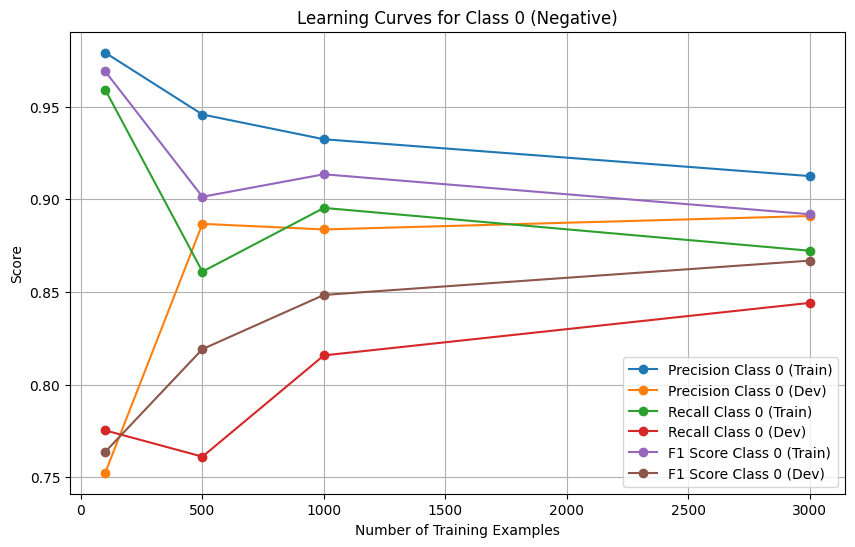

In [10]:
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, precision_train_0, label="Precision Class 0 (Train)", marker='o')
plt.plot(train_sizes, precision_dev_0, label="Precision Class 0 (Dev)", marker='o')
plt.plot(train_sizes, recall_train_0, label="Recall Class 0 (Train)", marker='o')
plt.plot(train_sizes, recall_dev_0, label="Recall Class 0 (Dev)", marker='o')
plt.plot(train_sizes, f1_train_0, label="F1 Score Class 0 (Train)", marker='o')
plt.plot(train_sizes, f1_dev_0, label="F1 Score Class 0 (Dev)", marker='o')
plt.title("Learning Curves for Class 0 (Negative)")
plt.xlabel("Number of Training Examples")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

Evaluating on test data

In [11]:
nb_model_full = NaiveBayes(alpha=1)
nb_model_full.fit(X_train.toarray(), y_train)

y_pred_test = nb_model_full.predict(X_test.toarray())
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_test, average=None, labels=[0, 1])
micro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='micro')
macro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='macro')

print("\nTest Data Precision, Recall, F1 Scores:")
print(f"Class 0: Precision: {precision[0]:.2f}, Recall: {recall[0]:.2f}, F1: {f1[0]:.2f}")
print(f"Class 1: Precision: {precision[1]:.2f}, Recall: {recall[1]:.2f}, F1: {f1[1]:.2f}")
print(f"Micro Average: Precision: {micro_avg[0]:.2f}, Recall: {micro_avg[1]:.2f}, F1: {micro_avg[2]:.2f}")
print(f"Macro Average: Precision: {macro_avg[0]:.2f}, Recall: {macro_avg[1]:.2f}, F1: {macro_avg[2]:.2f}")


Test Data Precision, Recall, F1 Scores:
Class 0: Precision: 0.89, Recall: 0.86, F1: 0.88
Class 1: Precision: 0.86, Recall: 0.89, F1: 0.87
Micro Average: Precision: 0.88, Recall: 0.88, F1: 0.88
Macro Average: Precision: 0.88, Recall: 0.88, F1: 0.88
